# 28 — Physical units: h_rss benchmarks, other burst sources, and the sensitive range for binary black holes

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extensions 15, 14 and 16 convert the "SNR at 50 % efficiency" of the project into physical units.

* **15. LVK-style benchmark.** Sine-Gaussians with Q = 9 at f₀ = 70, 100, 153, 235, 361 Hz and Gaussian pulses of several widths: efficiency against the root-sum-square strain h_rss (of the detector response, optimally oriented, linear polarisation) for the sine-Gaussian bank, the fresh-injection CNN and excess power, at FAP 10⁻² and 10⁻³ (validation thresholds). h_rss at 50 % efficiency is ρ₅₀ divided by the SNR per unit h_rss, computed with the PSD of the test chunks.
* **14. Other burst sources.** Damped sinusoids (black-hole ringdowns), cosmic-string cusps (f^{-4/3} up to a high-frequency cutoff) and band-limited white-noise bursts — shapes that are not in the training prior of the networks nor in the sine-Gaussian bank.
* **16. Physical injections for black-hole binaries.** 600 IMRPhenomD sources at 1 Mpc (masses, spins, inclination, sky position and polarisation of the library prior, H1 antenna pattern, **no rescaling**) give the optimal SNR ρ(D) = ρ₁ Mpc / D in the real PSD of the test chunks; combined with the efficiency curves of notebook 08 (IMR bank, CNN trained with IMR) they give the detection probability against distance, the sensitive range and the sensitive volume per year. A check against GW150914 (SNR ≈ 19 in H1 at ≈ 410 Mpc) is included.

**What it does not do.** Euclidean volume (no cosmology: the masses are detector-frame and distances up to ≈ 1 Gpc have z ≈ 0.2), single detector H1, no network or duty-cycle factors, efficiency depends on ρ only (the curves of notebook 08 averaged over the library); the O1 PSD is that of 8 chunks, not the sensitivity of a design detector.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, pickle, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seq_models as sm
import imr_tools as it
import gwosc_tools as g
g.style()
rng = np.random.default_rng(28)
CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
V, ID = {}, {}
for sp in ("train", "val", "test"): V[sp], ID[sp], _ = g.load_split(sp)
S1te = np.stack([CH[i]["S1"] for i in ID["test"]]); S1med = np.median(np.stack([CH[i]["S1"] for i in g.SPLIT["test"]]), 0)
NETS = [sm.train_variant("cnn_fresh", None, None, seed=s, verbose=False)[0] for s in (0, 1)]
logit = lambda v: np.mean([m.predict(sm.clip(v)[..., None], verbose=0, batch_size=1024)[:, 0] for m in NETS], 0)
EP = g.ExcessPower().fit(V["train"])
BKT = {c: g.SGBank(CH[c]["S1"]) for c in CH}
def scores(ser, cid): return dict(bank=g.scan_mixed(ser, cid, BKT)["rho2"], cnn=logit(ser), ep=EP.stat(ser))
d = np.load(os.path.join(g.CACHE, "scan03_val.npz")); VAL = {"bank": d["rho2"], "cnn": logit(V["val"]), "ep": EP.stat(V["val"])}
F = g.FREQ

## Waveforms in the frequency domain (unit amplitude of the detector response)

In [2]:
def wf_sg(f0, Q): return g.sine_gaussian_ft(F, f0, Q, 0.0, positive_only=True)
def wf_pulse(sig): return g.gaussian_pulse_ft(F, sig)
def wf_ring(f0, tau): w0 = 2 * np.pi * f0; return w0 / ((1 / tau + 2j * np.pi * F) ** 2 + w0 ** 2)
def wf_cusp(fh, fl=30.0): return np.where((F >= fl) & (F <= fh), np.where(F > 0, F, 1.0) ** (-4 / 3), 0.0).astype(complex)
def wf_wnb(f1, df): return np.where((F >= f1) & (F <= f1 + df), 1.0, 0.0).astype(complex)       # random phases drawn at injection
def hrss(H): return float(np.sqrt(2 * np.sum(np.abs(H[1:]) ** 2)))            # root-sum-square strain of a real signal with spectrum H on the 1 Hz bins (both signs of frequency)
def rho_per_hrss(H): return float(np.sqrt(4 * np.sum(np.abs(H) ** 2 * g.BAND / S1med))) / hrss(H)
CLASSES = {}
for f0 in (70, 100, 153, 235, 361): CLASSES[f"sine-Gaussian Q=9, f0={f0} Hz"] = ("LVK", lambda f0=f0: wf_sg(f0, 9.0), False)
for sig in (0.1e-3, 0.5e-3, 2.5e-3): CLASSES[f"Gaussian pulse, sigma={sig * 1e3:g} ms"] = ("LVK", lambda s=sig: wf_pulse(s), False)
for f0, tau in ((100, 10e-3), (200, 5e-3), (300, 3e-3)): CLASSES[f"ringdown f={f0} Hz, tau={tau * 1e3:g} ms"] = ("other", lambda f0=f0, tau=tau: wf_ring(f0, tau), False)
for fh in (150, 300, 500): CLASSES[f"cosmic-string cusp, f_high={fh} Hz"] = ("other", lambda fh=fh: wf_cusp(fh), False)
for f1, df in ((100, 100), (100, 400)): CLASSES[f"white-noise burst {f1}-{f1 + df} Hz"] = ("other", lambda f1=f1, df=df: wf_wnb(f1, df), True)
print({k: (round(hrss(v[1]()) , 3), round(rho_per_hrss(v[1]()) * 1e-22, 3)) for k, v in list(CLASSES.items())[:3]}, "(hrss of unit waveform, rho per 1e-22 hrss)")

{'sine-Gaussian Q=9, f0=70 Hz': (0.135, 13.277), 'sine-Gaussian Q=9, f0=100 Hz': (0.113, 16.912), 'sine-Gaussian Q=9, f0=153 Hz': (0.091, 18.191)} (hrss of unit waveform, rho per 1e-22 hrss)


In [3]:
SNR_B = [3, 4, 5, 6, 7, 8, 10, 12, 16, 24]; NINJ = 200; fn = os.path.join(g.CACHE, "stats28.pkl")
def inject_class(H0, rnd, norm, n):
    i = rng.choice(len(V["test"]), n, replace=False); H = np.tile(H0, (n, 1)).astype(complex)
    if rnd: H = H * np.exp(2j * np.pi * rng.uniform(size=H.shape))
    H = H * np.exp(-2j * np.pi * F[None, :] * rng.uniform(0.3, 0.7, n)[:, None]) / np.sqrt(S1te[i]) * g.BAND
    H = H * (norm / np.sqrt(np.sum(np.abs(H) ** 2 * 4, axis=1)))[:, None]      # V = 2H/sqrt(S1): sum|V|^2 = norm^2
    return g.to_series(g.to_bins(V["test"][i]) + 2 * H), ID["test"][i]
if os.path.exists(fn): RES = pickle.load(open(fn, "rb"))
else:
    RES = {}
    for name, (grp, mk, rnd) in CLASSES.items():
        for s in SNR_B:
            ser, cid = inject_class(mk(), rnd, float(s), NINJ); RES[(name, s)] = scores(ser, cid)
    pickle.dump(RES, open(fn, "wb"))
rows = []
for name, (grp, mk, rnd) in CLASSES.items():
    H0 = mk(); k_ = rho_per_hrss(H0)
    for det in ("bank", "cnn", "ep"):
        for far in (1e-2, 1e-3):
            thr = g.threshold_at_far(VAL[det], far); e = [float((RES[(name, s)][det] > thr).mean()) for s in SNR_B]; r50 = g.snr_level(e, SNR_B, .5)
            rows.append(dict(group=grp, waveform=name, detector=det, FAP=far, rho50=r50, hrss50_1e22=r50 / k_ / 1e-22 if np.isfinite(r50) else np.nan, eff_rho8=float(np.interp(8, SNR_B, e))))
HR = pd.DataFrame(rows); T = HR[HR.FAP == 1e-2].pivot_table(index=["group", "waveform"], columns="detector", values="hrss50_1e22").round(2); print("h_rss at 50 % efficiency [1e-22 Hz^-1/2], FAP 1e-2 (NaN: does not reach 50 % up to rho = 24)"); T

h_rss at 50 % efficiency [1e-22 Hz^-1/2], FAP 1e-2 (NaN: does not reach 50 % up to rho = 24)


detector                                 bank   cnn    ep
group waveform                                           
LVK   Gaussian pulse, sigma=0.1 ms       0.38  0.35  0.35
      Gaussian pulse, sigma=0.5 ms       0.38  0.31  0.35
      Gaussian pulse, sigma=2.5 ms       0.67  0.47  0.71
      sine-Gaussian Q=9, f0=100 Hz       0.29  0.25  0.41
      sine-Gaussian Q=9, f0=153 Hz       0.27  0.25  0.34
      sine-Gaussian Q=9, f0=235 Hz       0.29  0.29  0.34
      sine-Gaussian Q=9, f0=361 Hz       0.34  0.38  0.37
      sine-Gaussian Q=9, f0=70 Hz        0.38  0.32  0.58
other cosmic-string cusp, f_high=150 Hz  0.57  0.38  0.58
      cosmic-string cusp, f_high=300 Hz  0.56  0.37  0.52
      cosmic-string cusp, f_high=500 Hz  0.56  0.37  0.53
      ringdown f=100 Hz, tau=10 ms       0.33  0.27  0.37
      ringdown f=200 Hz, tau=5 ms        0.31  0.28  0.31
      ringdown f=300 Hz, tau=3 ms        0.33  0.31  0.33
      white-noise burst 100-200 Hz       0.83  0.57  1.04
      white-noise burst 100-500 Hz       1.39   NaN  1.22

In [4]:
print("rho50 (FAP 1e-2):"); HR[HR.FAP == 1e-2].pivot_table(index=["group", "waveform"], columns="detector", values="rho50").round(2)

rho50 (FAP 1e-2):


detector                                  bank    cnn     ep
group waveform                                              
LVK   Gaussian pulse, sigma=0.1 ms        5.65   5.23   5.13
      Gaussian pulse, sigma=0.5 ms        5.66   4.56   5.15
      Gaussian pulse, sigma=2.5 ms        5.25   3.64   5.59
      sine-Gaussian Q=9, f0=100 Hz        4.95   4.21   6.96
      sine-Gaussian Q=9, f0=153 Hz        4.97   4.53   6.20
      sine-Gaussian Q=9, f0=235 Hz        5.03   5.06   5.90
      sine-Gaussian Q=9, f0=361 Hz        4.95   5.53   5.34
      sine-Gaussian Q=9, f0=70 Hz         5.11   4.23   7.76
other cosmic-string cusp, f_high=150 Hz   5.61   3.75   5.76
      cosmic-string cusp, f_high=300 Hz   5.82   3.80   5.43
      cosmic-string cusp, f_high=500 Hz   5.84   3.88   5.51
      ringdown f=100 Hz, tau=10 ms        5.11   4.19   5.73
      ringdown f=200 Hz, tau=5 ms         5.25   4.75   5.24
      ringdown f=300 Hz, tau=3 ms         5.22   5.00   5.19
      white-noise burst 100-200 Hz       14.77  10.22  18.59
      white-noise burst 100-500 Hz       22.20    NaN  19.49

## 16. Sensitive range for binary black holes from physical injections

In [5]:
lib_rng = np.random.default_rng(16); n = 600
m_tot = lib_rng.uniform(30, 100, n); q = lib_rng.uniform(0.25, 1.0, n); m1 = m_tot / (1 + q); m2 = m_tot - m1
chi1, chi2 = lib_rng.uniform(-0.5, 0.5, n), lib_rng.uniform(-0.5, 0.5, n); cosi = lib_rng.uniform(-1, 1, n)
theta = np.arccos(lib_rng.uniform(-1, 1, n)); phis = lib_rng.uniform(0, 2 * np.pi, n); psi = lib_rng.uniform(0, np.pi, n); fp, fc = it.antenna(theta, phis, psi)
RHO1 = np.zeros(n); SCALE = it.FS_GEN          # one_waveform returns rfft(w)/FS_GEN of a window built with irfft: the physical continuous-FT amplitude needs one more factor FS_GEN
for i in range(n):
    H, _ = it.one_waveform(m1[i], m2[i], chi1[i], chi2[i], np.arccos(cosi[i]), fp[i], fc[i], 0.7)
    RHO1[i] = SCALE * np.sqrt(np.sum(4 * np.abs(H) ** 2 * g.BAND / S1med))
print("optimal SNR at 1 Mpc: median %.2f; optimally oriented 36+29 Msun face-on: " % np.median(RHO1), end="")
H, _ = it.one_waveform(36.0, 29.0, 0, 0, 0.0, 1.0, 0.0, 0.7); rho_gw150914_1mpc = SCALE * np.sqrt(np.sum(4 * np.abs(H) ** 2 * g.BAND / S1med)); print("%.1f  ->  SNR at 410 Mpc (face-on, F+=1, the optimum) = %.1f; the H1 matched-filter SNR of GW150914 was 19-20, reduced by the inclination and by F+" % (rho_gw150914_1mpc, rho_gw150914_1mpc / 410))

optimal SNR at 1 Mpc: median 4115.50; optimally oriented 36+29 Msun face-on: 14788.3  ->  SNR at 410 Mpc (face-on, F+=1, the optimum) = 36.1; the H1 matched-filter SNR of GW150914 was 19-20, reduced by the inclination and by F+


In [6]:
s8 = g.load_json("08_summary.json"); curves = {k: np.array(v) for k, v in s8["curves"].items()}; snr8 = np.array(s8["snrs"], float)
EFF = {("IMR bank", 1e-2): curves["IMR matched-filter bank@0.01"], ("IMR bank", 1e-3): curves["IMR matched-filter bank@0.001"], ("CNN trained with IMR", 1e-2): curves["CNN fresh + IMR (2 seeds)@0.01"], ("CNN trained with IMR", 1e-3): curves["CNN fresh + IMR (2 seeds)@0.001"]}
D = np.linspace(5, 3000, 3000)                                  # Mpc
rows = []; PD = {}
for (det, far), e in EFF.items():
    ecur = np.maximum.accumulate(e); eff_of_rho = lambda r: np.interp(r, snr8, ecur, left=0.0, right=1.0)
    p_det = np.array([[eff_of_rho(r1 / d) for d in D] for r1 in RHO1]).mean(0); PD[(det, far)] = p_det
    V_ = np.trapezoid(p_det * 4 * np.pi * D ** 2, D); R_eff = (3 * V_ / (4 * np.pi)) ** (1 / 3)
    mass_bins = [(30, 50), (50, 75), (75, 100)]
    for lo, hi in mass_bins:
        m = (m_tot >= lo) & (m_tot < hi); pm = np.array([[eff_of_rho(r1 / d) for d in D] for r1 in RHO1[m]]).mean(0); Vm = np.trapezoid(pm * 4 * np.pi * D ** 2, D)
        rows.append(dict(detector=det, FAP=far, mass=f"{lo}-{hi}", range_Mpc=(3 * Vm / (4 * np.pi)) ** (1 / 3), VT_Gpc3_yr=Vm * 1e-9))
    rows.append(dict(detector=det, FAP=far, mass="30-100 (all)", range_Mpc=R_eff, VT_Gpc3_yr=V_ * 1e-9))
RG = pd.DataFrame(rows); print("sensitive range (Euclidean, volume-averaged over orientation and the library prior) and volume per year of observing time (single H1):"); RG.round(1)

sensitive range (Euclidean, volume-averaged over orientation and the library prior) and volume per year of observing time (single H1):


,detector,FAP,mass,range_Mpc,VT_Gpc3_yr
0,IMR bank,0.0,30-50,801.9,2.2
1,IMR bank,0.0,50-75,1266.0,8.5
2,IMR bank,0.0,75-100,1557.0,15.8
3,IMR bank,0.0,30-100 (all),1305.5,9.3
4,IMR bank,0.0,30-50,661.9,1.2
5,IMR bank,0.0,50-75,1060.6,5.0
6,IMR bank,0.0,75-100,1326.3,9.8
7,IMR bank,0.0,30-100 (all),1104.0,5.6
8,CNN trained with IMR,0.0,30-50,1028.2,4.6
9,CNN trained with IMR,0.0,50-75,1553.1,15.7


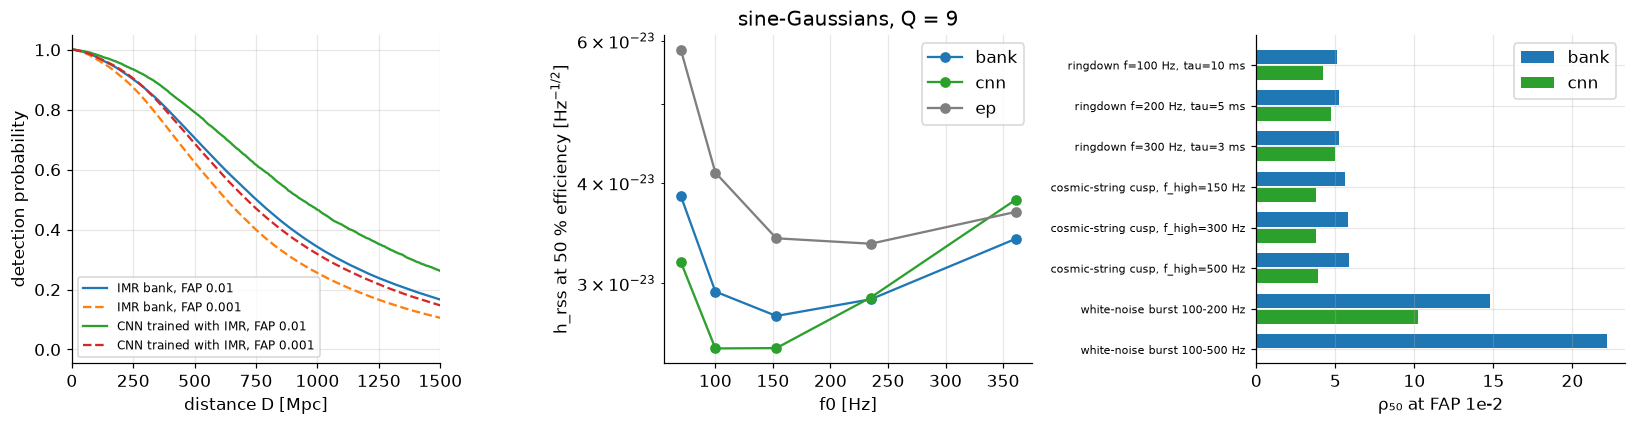

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for (det, far), p in PD.items(): ax[0].plot(D, p, label=f"{det}, FAP {far:g}", ls="-" if far == 1e-2 else "--")
ax[0].set_xlabel("distance D [Mpc]"); ax[0].set_ylabel("detection probability"); ax[0].set_xlim(0, 1500); ax[0].legend(fontsize=8)
T2 = HR[(HR.FAP == 1e-2) & HR.waveform.str.contains("sine-Gaussian")]
for det, c in (("bank", g.COLORS["freq"]), ("cnn", "C2"), ("ep", g.COLORS["grey"])):
    s = T2[T2.detector == det]; ax[1].semilogy([int(w.split("f0=")[1].split()[0]) for w in s.waveform], s.hrss50_1e22 * 1e-22, "o-", color=c, label=det)
ax[1].set_xlabel("f0 [Hz]"); ax[1].set_ylabel("h_rss at 50 % efficiency [Hz$^{-1/2}$]"); ax[1].legend(); ax[1].set_title("sine-Gaussians, Q = 9")
sub = HR[(HR.FAP == 1e-2) & (HR.group == "other") & (HR.detector.isin(["bank", "cnn"]))]; lab = sub.waveform.unique()
for k, det in enumerate(("bank", "cnn")): ax[2].barh(np.arange(len(lab)) + 0.2 * (2 * k - 1), [sub[(sub.waveform == w) & (sub.detector == det)].rho50.values[0] for w in lab], height=0.35, color=g.COLORS["freq"] if det == "bank" else "C2", label=det)
ax[2].set_yticks(range(len(lab))); ax[2].set_yticklabels(lab, fontsize=7); ax[2].invert_yaxis(); ax[2].set_xlabel("ρ₅₀ at FAP 1e-2"); ax[2].legend()
fig.tight_layout(); g.savefig(fig, "fig28_physical_units"); plt.show()
g.save_json(dict(hrss=HR.to_dict("records"), snr_per_Mpc_median=float(np.median(RHO1)), gw150914_rho_per_Mpc=float(rho_gw150914_1mpc), range=RG.to_dict("records")), "28_summary.json")

## Output and next step

`results/28_summary.json`, `figures/fig28_physical_units`. Next: precessing / higher-mode waveforms (extension 10), then the Bayesian evidence and coherent analyses.